# Sensor Modalities: Camera, LiDAR and Radar

**Module 01 · Perception and Prediction** · Notebook 2 of 9

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/blob/main/01_Perception/02_sensor_modalities.ipynb)

| Level | Prerequisites | Standards |
|---|---|---|
| Beginner | [01 SAE levels and ODD](01_sae_levels_and_odd.ipynb) | ISO 21448:2022; ISO 26262-9:2018 (context) |

**Author:** Milin Patel · Hochschule Kempten · MIT Licence

## Learning objectives

By the end of this notebook you will be able to:

1. Describe the operating principles of camera, LiDAR and radar (incl. 4D imaging radar and FMCW LiDAR)
2. Read a real camera image and LiDAR scan from the KITTI dataset, project the LiDAR into the image and interpret depth and reflectance
3. Measure, rather than assume, how LiDAR point density and camera pixel coverage fall with distance
4. Identify, object by object, what each sensor misses in a real frame (distance, occlusion, field of view)
5. Compute the radar Doppler shift and explain what KITTI cannot tell you about radar and weather
6. Quantify how much redundancy two sensors really provide when their weaknesses share a cause

## Setup

In [1]:
# Course toolkit (tables, formulas and real-data loaders). Installs automatically on Colab.
try:
    import avsafety
except ImportError:
    %pip install -q "avsafety[data] @ git+https://github.com/milinpatel07/Autonomous-Driving_AI-Safety-and-Security.git"
    import avsafety
from avsafety import data as D

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display

rng = np.random.default_rng(42)
OKABE_ITO = ['#E69F00', '#56B4E9', '#009E73', '#F0E442', '#0072B2', '#D55E00', '#CC79A7', '#000000']
SENSOR_COLOURS = {'Camera': OKABE_ITO[0], 'LiDAR': OKABE_ITO[2], 'Radar': OKABE_ITO[4], 'Fusion': OKABE_ITO[6]}
CLASS_COLOURS = {'Car': OKABE_ITO[4], 'Van': OKABE_ITO[1], 'Truck': OKABE_ITO[1], 'Pedestrian': OKABE_ITO[5],
                 'Person_sitting': OKABE_ITO[5], 'Cyclist': OKABE_ITO[0], 'Tram': OKABE_ITO[7], 'Misc': OKABE_ITO[7]}
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': True, 'grid.alpha': 0.3})
print(f"NumPy {np.__version__}, avsafety {avsafety.__version__}")

NumPy 2.5.4, avsafety 1.1.0


### Data and licence

All measurements in this notebook come from the **KITTI object-detection benchmark** (training split), recorded in and around Karlsruhe with a Velodyne HDL-64E spinning LiDAR (64 beams, 10 Hz, 26.9° vertical field of view, mounted 1.73 m above the road), colour and greyscale cameras (1.4 MP, triggered when the LiDAR faces forward, mounted 1.65 m high) and a GPS/IMU unit (Geiger et al., 2013). KITTI has **no radar** and was recorded in daylight and dry weather — keep both limits in mind when reading the results.

The frames are fetched on demand (about 1–2 s per file, then cached). `FRAMES` lists the 30 frames used here: a seeded random draw (seed 0) from the KITTI training frames that contain at least two cars and at least two pedestrians or cyclists. The same list is used in [03 LiDAR and point clouds](03_lidar_point_clouds.ipynb) and [06 Sensor fusion](06_sensor_fusion.ipynb).

In [3]:
print(D.attribution('KITTI'))
FRAMES = [35, 134, 217, 274, 462, 1134, 1868, 2096, 2227, 3078, 3677, 3687, 4170, 4283, 4292,
          4520, 4651, 4755, 4804, 4972, 5259, 5430, 5622, 5838, 5920, 5934, 6333, 6511, 6785, 6916]
SHOWCASE = 462            # an urban street with cars and pedestrians at 23-49 m
try:
    fr = D.kitti_object(SHOWCASE)
except D.DataUnavailable as exc:
    raise SystemExit(f"KITTI could not be downloaded ({exc}). Run the notebook with internet access.")
print(f"Frame {fr.index}: image {fr.image.shape[1]} x {fr.image.shape[0]} px, "
      f"{len(fr.points):,} LiDAR points (x, y, z, reflectance), {len(fr.labels)} labelled objects")
print("Calibration matrices:", {k: v.shape for k, v in fr.calib.items()})

Data: KITTI Vision Benchmark Suite (Geiger et al., CVPR 2012 / IJRR 2013), CC BY-NC-SA 3.0, https://www.cvlibs.net/datasets/kitti/
Frame 000462: image 1242 x 375 px, 114,230 LiDAR points (x, y, z, reflectance), 13 labelled objects
Calibration matrices: {'P2': (3, 4), 'R0': (4, 4), 'Tr_velo_to_cam': (4, 4)}


---
## Part 1: Sensor comparison

Typical characteristics of automotive sensors. These are **vendor-level, order-of-magnitude figures** (they depend on the product, target reflectivity and conditions); the last column says where this notebook replaces a typical figure with a measurement from KITTI.

In [4]:
sensor_table = pd.DataFrame({
    'Sensor': ['Camera', 'LiDAR', 'Radar (conventional)', '4D imaging radar'],
    'Measures': ['Colour/intensity per pixel (2D)', 'Range + angle (+ reflectance) per point (3D)',
                 'Range, radial velocity, azimuth', 'Range, radial velocity, azimuth, elevation'],
    'Typical range (vendor)': ['Optics-dependent (~100 m+)', '~150-250 m at 10 % reflectivity (long-range units)',
                               '~200-300 m (long-range)', '~200-300 m (long-range)'],
    'Angular resolution (vendor)': ['High (megapixels)', 'High (~0.1-0.2 deg)', 'Low (several deg)', 'Medium (~1 deg)'],
    'Weather robustness': ['Poor in glare, fog, heavy rain, darkness', 'Degrades in fog, heavy rain, snow, spray',
                           'Good', 'Good'],
    'Measured in this notebook (KITTI)': ['Pixels on objects vs distance (Part 4)',
                                          'Points on objects, ground density, reflectance (Parts 2-4)',
                                          'Not measurable: KITTI has no radar (Part 6)', 'Not measurable (Part 6)'],
})
display(sensor_table)
print("--- Sensor comparison (text summary) ---")
for _, r in sensor_table.iterrows():
    print(f"  {r['Sensor']}: measures {r['Measures']}; range {r['Typical range (vendor)']}; "
          f"resolution {r['Angular resolution (vendor)']}; weather: {r['Weather robustness']}")

,Sensor,Measures,Typical range (vendor),Angular resolution (vendor),Weather robustness,Measured in this notebook (KITTI)
0,Camera,Colour/intensity per pixel (2D),Optics-dependent (~100 m+),High (megapixels),"Poor in glare, fog, heavy rain, darkness",Pixels on objects vs distance (Part 4)
1,LiDAR,Range + angle (+ reflectance) per point (3D),~150-250 m at 10 % reflectivity (long-range un...,High (~0.1-0.2 deg),"Degrades in fog, heavy rain, snow, spray","Points on objects, ground density, reflectance..."
2,Radar (conventional),"Range, radial velocity, azimuth",~200-300 m (long-range),Low (several deg),Good,Not measurable: KITTI has no radar (Part 6)
3,4D imaging radar,"Range, radial velocity, azimuth, elevation",~200-300 m (long-range),Medium (~1 deg),Good,Not measurable (Part 6)


--- Sensor comparison (text summary) ---
  Camera: measures Colour/intensity per pixel (2D); range Optics-dependent (~100 m+); resolution High (megapixels); weather: Poor in glare, fog, heavy rain, darkness
  LiDAR: measures Range + angle (+ reflectance) per point (3D); range ~150-250 m at 10 % reflectivity (long-range units); resolution High (~0.1-0.2 deg); weather: Degrades in fog, heavy rain, snow, spray
  Radar (conventional): measures Range, radial velocity, azimuth; range ~200-300 m (long-range); resolution Low (several deg); weather: Good
  4D imaging radar: measures Range, radial velocity, azimuth, elevation; range ~200-300 m (long-range); resolution Medium (~1 deg); weather: Good


### Camera
**Advantages:** high resolution (KITTI: 1.4 MP; current automotive cameras 8 MP and more), rich semantics (colour, texture, text on signs), low cost, excellent for classification.
**Disadvantages:** no direct depth (monocular), sensitive to illumination (night, glare, tunnels) and to fog, rain and dirt on the lens.

### LiDAR (Light Detection and Ranging)
**Advantages:** accurate 3D measurement (cm-level), independent of ambient light, high angular resolution, plus a reflectance value per point.
**Disadvantages:**
- Cost: from about US\$200 for 2025 automotive units (e.g. Hesai ATX, in mass production since 2025, [Reuters via LEDinside, Nov 2024](https://www.ledinside.com/node/34820)) up to tens of thousands of dollars for high-end or legacy spinning units such as the HDL-64E used in KITTI (as of October 2026).
- Degrades in fog, heavy rain, snow and spray (backscatter and attenuation).
- No colour; sparse at long range (measured below).
- Many designs have moving parts (spinning heads, polygon or MEMS mirrors); flash and optical-phased-array designs are fully solid-state.
- Range: ~150–250 m at 10 % reflectivity for long-range automotive units — always check the reflectivity at which a range is quoted.

Most LiDARs measure range by pulsed **time of flight**; **FMCW LiDAR** additionally measures radial velocity per point via the Doppler effect.

### Radar (Radio Detection and Ranging)
**Advantages:** robust in rain, fog and darkness; measures radial velocity **directly** (Doppler); long range; mature and low-cost.
**Disadvantages:**
- Low angular resolution; ghost targets from multipath reflections (e.g. guard rails, tunnels).
- Conventional automotive radar gives little or no elevation information (a bridge and a stopped truck can look similar); **4D imaging radar** adds elevation.
- Limited classification from sparse returns (micro-Doppler signatures and 4D radar improve this).

---
## Part 2: One real frame from two sensors

KITTI stores LiDAR points in the **sensor frame** of the Velodyne (x forward, y left, z up, origin at the sensor) and the labels in the **rectified camera frame** (x right, y down, z forward). The calibration gives the extrinsic transform `Tr_velo_to_cam`, the rectification `R0` and the camera projection matrix `P2`:

$$ \tilde{\mathbf u} = P_2\, R_0\, T_{velo\to cam}\, \tilde{\mathbf p}_{velo}, \qquad u = \tilde u_1/\tilde u_3,\; v = \tilde u_2/\tilde u_3 $$

The helper `fr.lidar_in_image()` applies exactly this chain and keeps the points that land inside the image. Below: the camera image, and a top view (bird's-eye view, BEV) of the full 360° scan with the camera's field of view and the labelled objects.

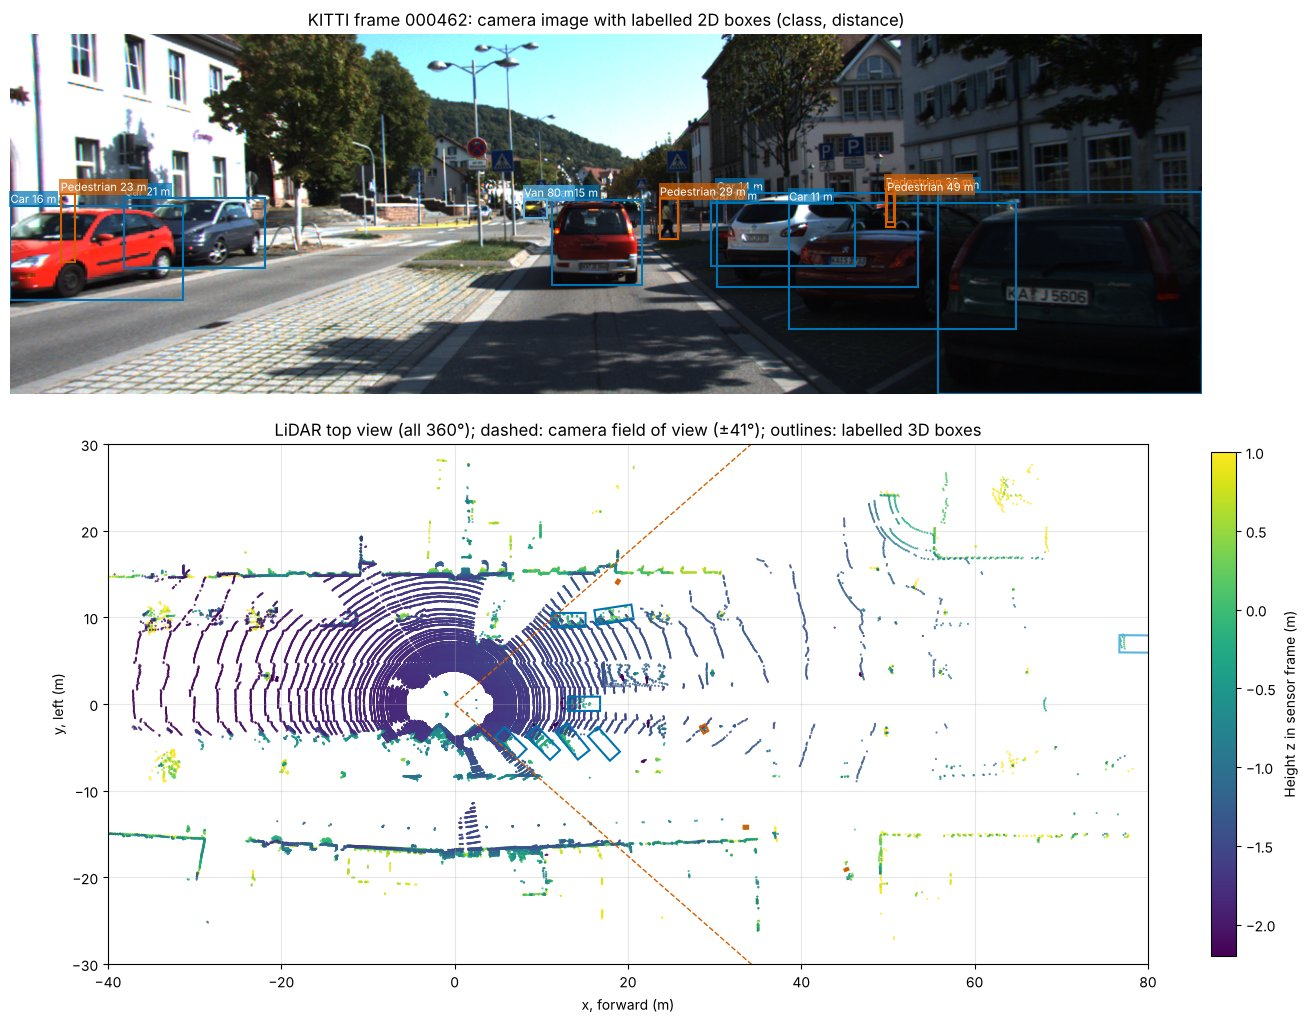

--- Real frame (text summary) ---
  LiDAR returns in this sweep: 114,230; median range 9.0 m; 99th percentile 55.7 m; maximum 80.0 m
  Returns inside the camera image: 17,974 (16 % of the sweep) - the other 84 % lie outside the camera's ±41° field of view
  Labelled objects: 12 (KITTI labels only objects visible in the camera image)


In [5]:
def label_footprint_velo(frame, lab):
    """Ground footprint (4 x 2, x/y in the LiDAR frame) of a KITTI 3D label."""
    corners = D.box3d_corners(lab).T                                    # 8 x 3, rectified camera frame
    to_velo = np.linalg.inv(frame.calib['R0'] @ frame.calib['Tr_velo_to_cam'])
    homo = np.c_[corners, np.ones(8)]
    return (to_velo @ homo.T).T[:4, :2]

pts = fr.points
uv, depth, pts_img = fr.lidar_in_image(max_depth=120)
objects = [l for l in fr.labels if l['type'] != 'DontCare']
fx, cx = fr.calib['P2'][0, 0], fr.calib['P2'][0, 2]
half_fov = np.degrees(np.arctan(max(cx, fr.image.shape[1] - cx) / fx))

fig = plt.figure(figsize=(15, 10))
ax0 = fig.add_axes([0.05, 0.62, 0.9, 0.36])
ax0.imshow(fr.image); ax0.set_axis_off()
for l in objects:
    ax0.add_patch(Rectangle((l['x1'], l['y1']), l['x2'] - l['x1'], l['y2'] - l['y1'], fill=False, lw=1.5,
                            edgecolor=CLASS_COLOURS.get(l['type'], 'white')))
    ax0.text(l['x1'], l['y1'] - 3, f"{l['type']} {np.hypot(l['x'], l['z']):.0f} m", fontsize=8,
             color='white', bbox=dict(facecolor=CLASS_COLOURS.get(l['type'], 'black'), alpha=0.7, pad=1, lw=0))
ax0.set_title(f'KITTI frame {fr.index}: camera image with labelled 2D boxes (class, distance)')

ax1 = fig.add_axes([0.08, 0.05, 0.84, 0.52])
sc = ax1.scatter(pts[:, 0], pts[:, 1], c=np.clip(pts[:, 2], -2.2, 1.0), s=0.2, cmap='viridis')
for l in objects:
    fp = label_footprint_velo(fr, l)
    ax1.fill(fp[:, 0], fp[:, 1], fill=False, lw=1.5, edgecolor=CLASS_COLOURS.get(l['type'], 'black'))
r_fov = 80
for s in (-1, 1):
    ax1.plot([0, r_fov * np.cos(np.radians(half_fov))], [0, s * r_fov * np.sin(np.radians(half_fov))],
             ls='--', color=OKABE_ITO[5], lw=1)
ax1.set_xlim(-40, 80); ax1.set_ylim(-30, 30); ax1.set_aspect('equal')
ax1.set_xlabel('x, forward (m)'); ax1.set_ylabel('y, left (m)')
ax1.set_title(f"LiDAR top view (all 360°); dashed: camera field of view (±{half_fov:.0f}°); outlines: labelled 3D boxes")
fig.colorbar(sc, ax=ax1, label='Height z in sensor frame (m)', fraction=0.02)
plt.show()

rng_xy = np.hypot(pts[:, 0], pts[:, 1])
print("--- Real frame (text summary) ---")
print(f"  LiDAR returns in this sweep: {len(pts):,}; median range {np.median(rng_xy):.1f} m; "
      f"99th percentile {np.percentile(rng_xy, 99):.1f} m; maximum {rng_xy.max():.1f} m")
print(f"  Returns inside the camera image: {len(uv):,} ({100 * len(uv) / len(pts):.0f} % of the sweep) - "
      f"the other {100 - 100 * len(uv) / len(pts):.0f} % lie outside the camera's ±{half_fov:.0f}° field of view")
print(f"  Labelled objects: {len(objects)} (KITTI labels only objects visible in the camera image)")

### LiDAR projected into the image

Colouring each projected point by its depth shows the core difference between the modalities: the camera has a value for **every pixel** but no measured depth; the LiDAR has a precise depth for a **sparse** set of pixels, arranged in 64 scan lines.

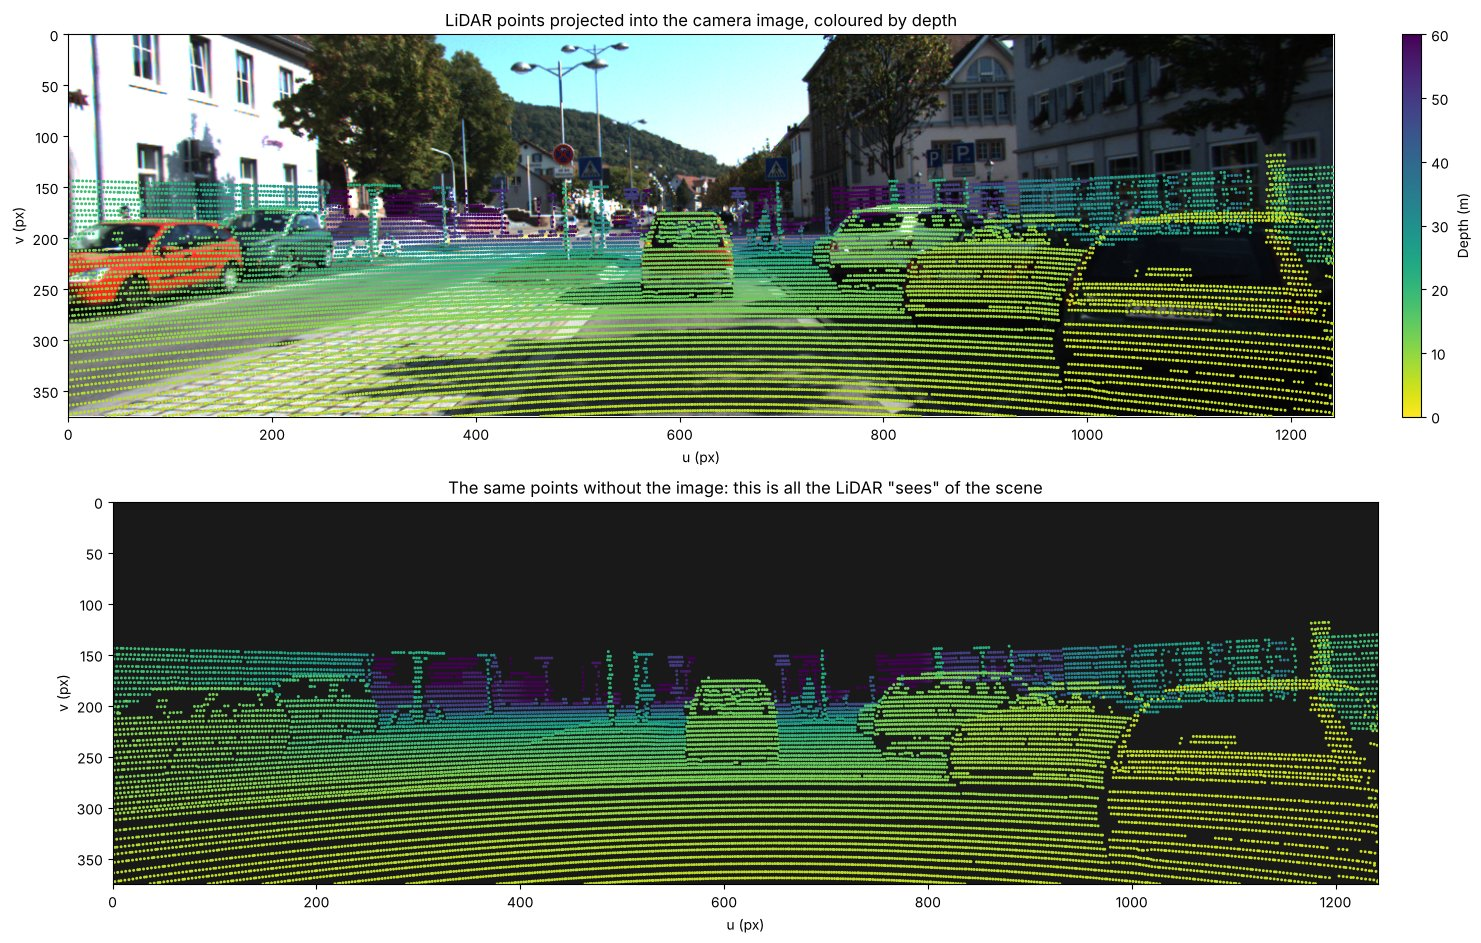

--- Camera vs LiDAR sampling (text summary) ---
  Image pixels: 465,750; pixels with at least one LiDAR point: 17,932 (3.9 %)
  Rows above v = 118 px (31 % of the image height) contain no LiDAR point at all: the HDL-64E looks at most ~2° upwards, so tall or close-by structures above that are seen by the camera only.
  Depth of projected points: 4.5 to 78.0 m


In [6]:
H, W = fr.image.shape[:2]
fig, axes = plt.subplots(2, 1, figsize=(15, 9.5))
axes[0].imshow(fr.image)
sc = axes[0].scatter(uv[:, 0], uv[:, 1], c=depth, s=1.2, cmap='viridis_r', vmin=0, vmax=60)
axes[0].set_title('LiDAR points projected into the camera image, coloured by depth')
fig.colorbar(sc, ax=axes[0], label='Depth (m)', fraction=0.02)
axes[1].imshow(np.full_like(fr.image, 25))
axes[1].scatter(uv[:, 0], uv[:, 1], c=depth, s=1.2, cmap='viridis_r', vmin=0, vmax=60)
axes[1].set_title('The same points without the image: this is all the LiDAR "sees" of the scene')
for ax in axes:
    ax.set_xlim(0, W); ax.set_ylim(H, 0); ax.set_xlabel('u (px)'); ax.set_ylabel('v (px)'); ax.grid(False)
plt.tight_layout(); plt.show()

covered = np.zeros((H, W), bool)
covered[uv[:, 1].astype(int), uv[:, 0].astype(int)] = True
row_has = covered.any(axis=1)
top_row = np.argmax(row_has)
print("--- Camera vs LiDAR sampling (text summary) ---")
print(f"  Image pixels: {H * W:,}; pixels with at least one LiDAR point: {covered.sum():,} "
      f"({100 * covered.mean():.1f} %)")
print(f"  Rows above v = {top_row} px ({100 * top_row / H:.0f} % of the image height) contain no LiDAR point at all: "
      "the HDL-64E looks at most ~2° upwards, so tall or close-by structures above that are seen by the camera only.")
print(f"  Depth of projected points: {depth.min():.1f} to {depth.max():.1f} m")

---
## Part 3: Reflectance — the LiDAR's "fourth channel"

Besides x, y, z, KITTI stores a **reflectance** value (0–1) per point: the strength of the return, which depends on the surface material, the incidence angle and the range. Retro-reflective materials (number plates, traffic signs, lane markings, reflective strips on clothing) return far more light than asphalt or dark paint. Reflectance is useful (lane markings, sign detection) and is also a SOTIF concern: very strong returns can saturate the receiver (blooming), and dark, specular or wet surfaces return almost nothing.

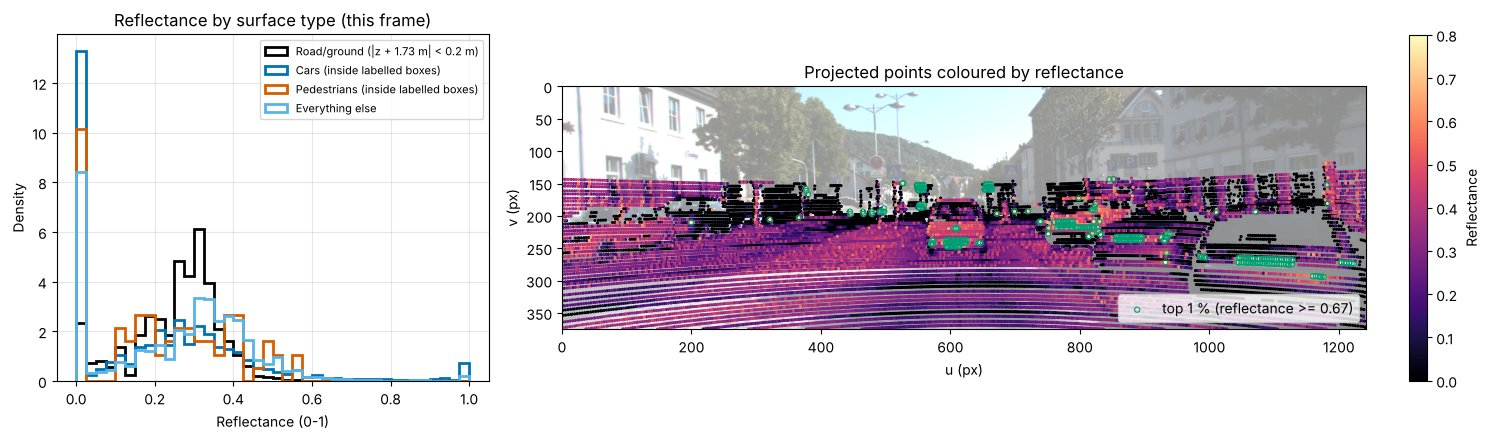

--- Reflectance (text summary) ---
  Road/ground (|z + 1.73 m| < 0.2 m)      : 48,335 points, median reflectance 0.28, 90th percentile 0.37
  Cars (inside labelled boxes)            :  5,981 points, median reflectance 0.20, 90th percentile 0.47
  Pedestrians (inside labelled boxes)     :     75 points, median reflectance 0.21, 90th percentile 0.45
  Everything else                         : 59,825 points, median reflectance 0.30, 90th percentile 0.47
  Top-1 % returns (>= 0.67): 1176 points, 21 % of them inside labelled objects (number plates, lights) - the rest on signs, posts and markings.


In [7]:
def points_in_label(frame, rect, lab, margin=0.1):
    """Boolean mask of points (given in rectified camera coordinates) inside a KITTI 3D box."""
    ry = lab['rotation_y']
    rot = np.array([[np.cos(ry), 0, np.sin(ry)], [0, 1, 0], [-np.sin(ry), 0, np.cos(ry)]])
    loc = (rect - np.array([lab['x'], lab['y'], lab['z']])) @ rot      # box frame: x along length, y down
    return ((np.abs(loc[:, 0]) <= lab['l'] / 2 + margin) & (loc[:, 1] <= margin) &
            (loc[:, 1] >= -lab['h'] - margin) & (np.abs(loc[:, 2]) <= lab['w'] / 2 + margin))

rect_all = fr.velo_to_rect(pts)
refl = pts[:, 3]
on_obj = np.zeros(len(pts), bool); obj_class = np.full(len(pts), '', dtype=object)
for l in objects:
    m = points_in_label(fr, rect_all, l); on_obj |= m; obj_class[m] = l['type']
ground = (np.abs(pts[:, 2] + 1.73) < 0.2) & ~on_obj
groups = {'Road/ground (|z + 1.73 m| < 0.2 m)': ground, 'Cars (inside labelled boxes)': obj_class == 'Car',
          'Pedestrians (inside labelled boxes)': obj_class == 'Pedestrian', 'Everything else': ~on_obj & ~ground}
hi_thr = np.percentile(refl, 99)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={'width_ratios': [1, 2]})
for (name, m), col in zip(groups.items(), [OKABE_ITO[7], OKABE_ITO[4], OKABE_ITO[5], OKABE_ITO[1]]):
    if m.sum():
        axes[0].hist(refl[m], bins=np.linspace(0, 1, 41), density=True, histtype='step', lw=2, color=col, label=name)
axes[0].set_xlabel('Reflectance (0-1)'); axes[0].set_ylabel('Density'); axes[0].legend(fontsize=8)
axes[0].set_title('Reflectance by surface type (this frame)')
in_img_refl = pts_img[:, 3]
axes[1].imshow(fr.image, alpha=0.45)
order = np.argsort(in_img_refl)
sc = axes[1].scatter(uv[order, 0], uv[order, 1], c=in_img_refl[order], s=1.5, cmap='magma', vmin=0, vmax=0.8)
hi = in_img_refl >= hi_thr
axes[1].scatter(uv[hi, 0], uv[hi, 1], s=14, facecolors='none', edgecolors=OKABE_ITO[2], lw=0.8,
                label=f'top 1 % (reflectance >= {hi_thr:.2f})')
axes[1].set_xlim(0, W); axes[1].set_ylim(H, 0); axes[1].grid(False); axes[1].legend(loc='lower right')
axes[1].set_title('Projected points coloured by reflectance'); axes[1].set_xlabel('u (px)'); axes[1].set_ylabel('v (px)')
fig.colorbar(sc, ax=axes[1], label='Reflectance', fraction=0.02)
plt.tight_layout(); plt.show()

print("--- Reflectance (text summary) ---")
for name, m in groups.items():
    if m.sum():
        print(f"  {name:40s}: {m.sum():6,d} points, median reflectance {np.median(refl[m]):.2f}, "
              f"90th percentile {np.percentile(refl[m], 90):.2f}")
share_hi_cars = (on_obj & (refl >= hi_thr)).sum() / max((refl >= hi_thr).sum(), 1)
print(f"  Top-1 % returns (>= {hi_thr:.2f}): {(refl >= hi_thr).sum()} points, {100 * share_hi_cars:.0f} % of them "
      "inside labelled objects (number plates, lights) - the rest on signs, posts and markings.")

---
## Part 4: How density falls with distance — measured

A spinning LiDAR fires beams at fixed angular steps, so neighbouring points move apart linearly with range. On a surface **facing** the sensor (the back of a car, a pedestrian) the number of points therefore falls roughly with $1/d^2$. On the **ground**, hit at a grazing angle, the spacing between consecutive rings grows with $d^2/h$ (h = sensor height), so ground density falls even faster, roughly with $1/d^3$. A camera behaves like the first case: the pixel area of an object falls with $1/d^2$.

We check both claims on real data: ground-return density in this frame, and points / pixels on all labelled objects in the 30 frames.

In [8]:
# (a) Ground returns per m^2 in range annuli (360 deg; occlusion shadows included)
edges = np.arange(4, 52, 2.0)
gmask = np.abs(pts[:, 2] + 1.73) < 0.25
r_g = np.hypot(pts[gmask, 0], pts[gmask, 1])
counts, _ = np.histogram(r_g, bins=edges)
area = np.pi * (edges[1:] ** 2 - edges[:-1] ** 2)
dens = counts / area
mid = (edges[1:] + edges[:-1]) / 2
ok = (dens > 0) & (mid >= 6) & (mid <= 40)
k_ground, a_ground = np.polyfit(np.log(mid[ok]), np.log(dens[ok]), 1)

# (b) Points and pixels on labelled objects across all 30 frames
rows = []
for f in FRAMES:
    try:
        fk = D.kitti_object(f, parts=('points', 'labels', 'calib'))
    except D.DataUnavailable as exc:
        print(f"frame {f} skipped: {exc}"); continue
    rect = fk.velo_to_rect(fk.points)
    for l in fk.labels:
        if l['type'] in ('DontCare', 'Misc', 'Tram'):
            continue
        n = int(points_in_label(fk, rect, l).sum())
        rows.append({'frame': f, 'class': {'Van': 'Car', 'Truck': 'Car', 'Person_sitting': 'Pedestrian'}.get(l['type'], l['type']),
                     'distance_m': float(np.hypot(l['x'], l['z'])), 'occluded': l['occluded'],
                     'truncated': l['truncated'], 'box_height_px': l['y2'] - l['y1'],
                     'box_area_px': (l['x2'] - l['x1']) * (l['y2'] - l['y1']), 'lidar_points': n,
                     'difficulty': D.kitti_difficulty(l)})
obj = pd.DataFrame(rows)
print(f"{len(obj)} labelled objects in {obj['frame'].nunique()} frames: " +
      ", ".join(f"{k} {v}" for k, v in obj['class'].value_counts().items()))

259 labelled objects in 30 frames: Car 146, Pedestrian 71, Cyclist 42


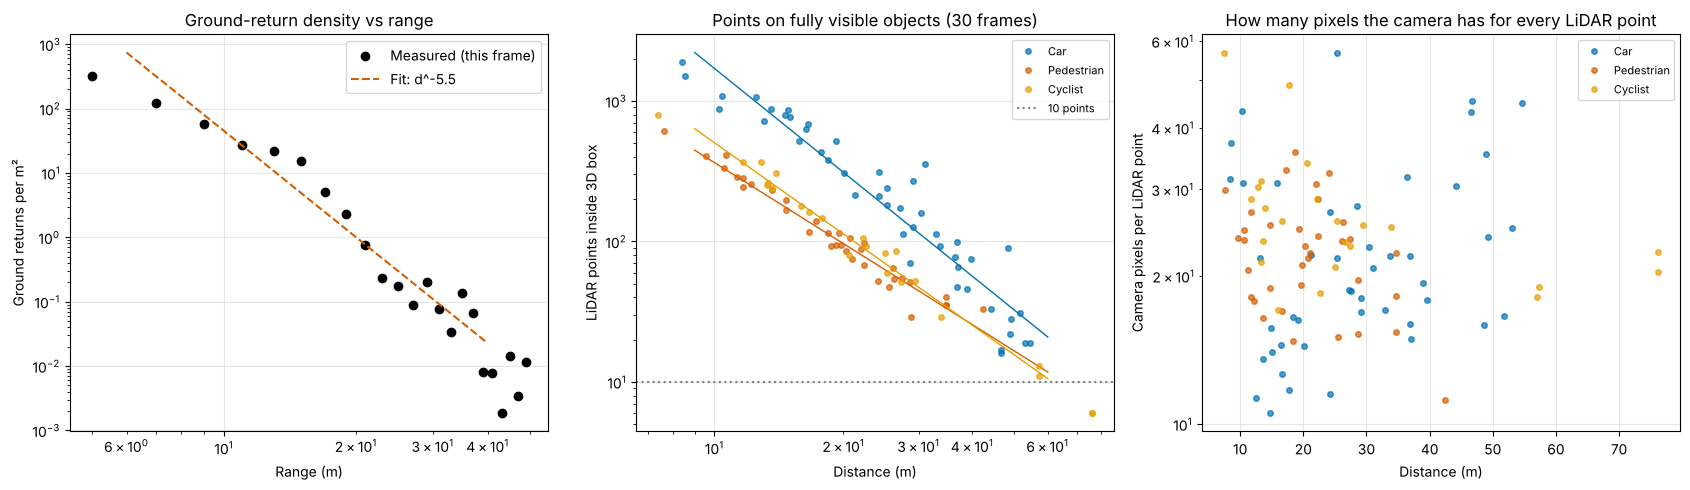

--- Density vs distance (text summary, measured) ---
  Ground returns fall with d^-5.48 between 6 and 40 m (grazing incidence; 1/d^3 expected).
  Car       : points ~ d^-2.46; fitted 310 points at 20 m, 57 at 40 m (1/d^2 expected)
  Pedestrian: points ~ d^-1.92; fitted 97 points at 20 m, 26 at 40 m (1/d^2 expected)
  Cyclist   : points ~ d^-2.16; fitted 113 points at 20 m, 25 at 40 m (1/d^2 expected)
  Camera pixels per LiDAR point on visible objects: median 22 (interquartile 18-28); the ratio stays roughly constant with distance because both fall with 1/d^2.


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
axes[0].loglog(mid[dens > 0], dens[dens > 0], 'o', color=OKABE_ITO[7], label='Measured (this frame)')
dd = np.linspace(6, 40, 50)
axes[0].loglog(dd, np.exp(a_ground) * dd ** k_ground, '--', color=OKABE_ITO[5], label=f'Fit: d^{k_ground:.1f}')
axes[0].set_xlabel('Range (m)'); axes[0].set_ylabel('Ground returns per m²')
axes[0].set_title('Ground-return density vs range'); axes[0].legend()

fits = {}
vis = obj[(obj['occluded'] == 0) & (obj['truncated'] < 0.15) & (obj['lidar_points'] > 0)]
for cls, col in [('Car', OKABE_ITO[4]), ('Pedestrian', OKABE_ITO[5]), ('Cyclist', OKABE_ITO[0])]:
    s = vis[vis['class'] == cls]
    axes[1].loglog(s['distance_m'], s['lidar_points'], 'o', ms=4, color=col, alpha=0.7, label=cls)
    if len(s) >= 5:
        k, a = np.polyfit(np.log(s['distance_m']), np.log(s['lidar_points']), 1)
        fits[cls] = (k, a)
        axes[1].loglog(dd * 1.5, np.exp(a) * (dd * 1.5) ** k, '-', color=col, lw=1)
axes[1].axhline(10, color='grey', ls=':', label='10 points')
axes[1].set_xlabel('Distance (m)'); axes[1].set_ylabel('LiDAR points inside 3D box')
axes[1].set_title('Points on fully visible objects (30 frames)'); axes[1].legend(fontsize=8)

ratio = vis['box_area_px'] / vis['lidar_points']
for cls, col in [('Car', OKABE_ITO[4]), ('Pedestrian', OKABE_ITO[5]), ('Cyclist', OKABE_ITO[0])]:
    s = vis[vis['class'] == cls]
    axes[2].semilogy(s['distance_m'], s['box_area_px'] / s['lidar_points'], 'o', ms=4, color=col, alpha=0.7, label=cls)
axes[2].set_xlabel('Distance (m)'); axes[2].set_ylabel('Camera pixels per LiDAR point')
axes[2].set_title('How many pixels the camera has for every LiDAR point'); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

print("--- Density vs distance (text summary, measured) ---")
print(f"  Ground returns fall with d^{k_ground:.2f} between 6 and 40 m (grazing incidence; 1/d^3 expected).")
for cls, (k, a) in fits.items():
    n20, n40 = np.exp(a) * 20 ** k, np.exp(a) * 40 ** k
    print(f"  {cls:10s}: points ~ d^{k:.2f}; fitted {n20:.0f} points at 20 m, {n40:.0f} at 40 m (1/d^2 expected)")
print(f"  Camera pixels per LiDAR point on visible objects: median {ratio.median():.0f} "
      f"(interquartile {ratio.quantile(0.25):.0f}-{ratio.quantile(0.75):.0f}); "
      "the ratio stays roughly constant with distance because both fall with 1/d^2.")

The measured exponents are close to the geometric prediction but not identical: distant objects are more often partly hidden, the vertical beam spacing of the HDL-64E is not uniform, and pedestrians are thin, so a few beams more or less make a large relative difference. What matters for safety is the absolute number: compare the fitted counts at 40 m with the minimum number of points a detector needs.

---
## Part 5: What each sensor misses in this frame

For every labelled object in the showcase frame we compare what the camera has (2D box height in pixels; KITTI treats boxes below 25 px as too small to evaluate) with what the LiDAR has (points inside the 3D box).

,class,distance_m,occluded,truncated,box_height_px,lidar_points,difficulty,camera_weak (<25 px),lidar_weak (<10 points)
0,Car,7.7,0,0.2,210.4,1986,Moderate,False,False
1,Car,10.9,2,0.0,131.3,1248,Hard,False,False
2,Car,14.0,2,0.0,97.7,715,Hard,False,False
3,Car,14.7,0,0.0,88.8,791,Easy,False,False
4,Car,16.1,0,0.3,98.7,825,Hard,False,False
5,Car,17.6,2,0.0,66.4,56,Hard,False,False
6,Car,20.8,1,0.0,72.2,360,Moderate,False,False
7,Pedestrian,23.3,2,0.0,70.9,9,Hard,False,True
8,Pedestrian,28.6,0,0.0,42.3,51,Easy,False,False
9,Pedestrian,36.2,2,0.0,39.5,14,Hard,False,False


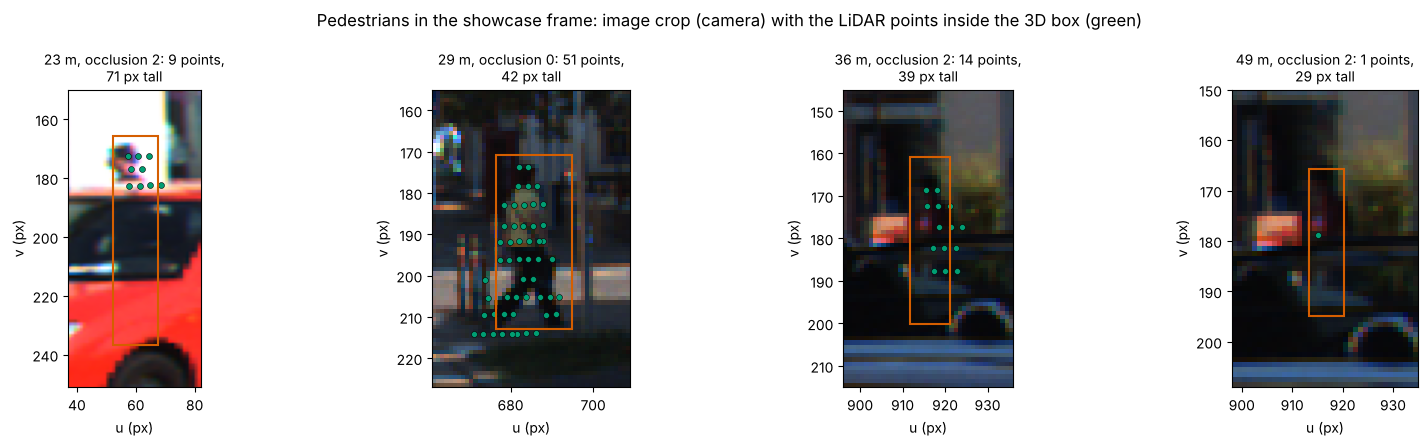

--- What each sensor misses in this frame (text summary) ---
  Car          7.7 m, occlusion 0:   210 px,  1986 points  
  Car         10.9 m, occlusion 2:   131 px,  1248 points  
  Car         14.0 m, occlusion 2:    98 px,   715 points  
  Car         14.7 m, occlusion 0:    89 px,   791 points  
  Car         16.1 m, occlusion 0:    99 px,   825 points  
  Car         17.6 m, occlusion 2:    66 px,    56 points  
  Car         20.8 m, occlusion 1:    72 px,   360 points  
  Pedestrian  23.3 m, occlusion 2:    71 px,     9 points  -> LiDAR weak
  Pedestrian  28.6 m, occlusion 0:    42 px,    51 points  
  Pedestrian  36.2 m, occlusion 2:    39 px,    14 points  
  Pedestrian  48.8 m, occlusion 2:    29 px,     1 points  -> LiDAR weak
  Car         79.5 m, occlusion 1:    19 px,    14 points  -> camera weak


In [10]:
this = obj[obj['frame'] == SHOWCASE].sort_values('distance_m').reset_index(drop=True)
this['camera_weak (<25 px)'] = this['box_height_px'] < 25
this['lidar_weak (<10 points)'] = this['lidar_points'] < 10
display(this[['class', 'distance_m', 'occluded', 'truncated', 'box_height_px', 'lidar_points', 'difficulty',
              'camera_weak (<25 px)', 'lidar_weak (<10 points)']].round(1))

# Crops of the pedestrians with their LiDAR points
peds = [l for l in objects if l['type'] == 'Pedestrian']
peds = sorted(peds, key=lambda l: l['z'])
fig, axes = plt.subplots(1, len(peds), figsize=(4 * len(peds), 4.5))
axes = np.atleast_1d(axes)
for ax, l in zip(axes, peds):
    m = points_in_label(fr, rect_all, l)
    pad = 15
    x1, y1, x2, y2 = int(l['x1']) - pad, int(l['y1']) - pad, int(l['x2']) + pad, int(l['y2']) + pad
    x1, y1 = max(x1, 0), max(y1, 0)
    ax.imshow(fr.image[y1:y2, x1:x2], extent=(x1, x1 + fr.image[y1:y2, x1:x2].shape[1], y1 + fr.image[y1:y2, x1:x2].shape[0], y1))
    puv = fr.rect_to_image(rect_all[m])
    ax.scatter(puv[:, 0], puv[:, 1], s=18, color=OKABE_ITO[2], edgecolors='black', lw=0.4)
    ax.add_patch(Rectangle((l['x1'], l['y1']), l['x2'] - l['x1'], l['y2'] - l['y1'], fill=False,
                           edgecolor=OKABE_ITO[5], lw=1.5))
    ax.set_title(f"{np.hypot(l['x'], l['z']):.0f} m, occlusion {l['occluded']}: {m.sum()} points,\n"
                 f"{l['y2'] - l['y1']:.0f} px tall", fontsize=10)
    ax.set_xlabel('u (px)'); ax.set_ylabel('v (px)'); ax.grid(False)
fig.suptitle('Pedestrians in the showcase frame: image crop (camera) with the LiDAR points inside the 3D box (green)')
plt.tight_layout(); plt.show()

print("--- What each sensor misses in this frame (text summary) ---")
for _, r in this.iterrows():
    flags = [s for s, f in [('camera weak', r['camera_weak (<25 px)']), ('LiDAR weak', r['lidar_weak (<10 points)'])] if f]
    print(f"  {r['class']:10s} {r['distance_m']:5.1f} m, occlusion {r['occluded']}: {r['box_height_px']:5.0f} px, "
          f"{r['lidar_points']:5d} points  {'-> ' + ' and '.join(flags) if flags else ''}")

### Across all 30 frames: when do the sensors struggle together?

A fusion system relies on one sensor covering for the other. That only works if their weak spots are **not** caused by the same thing. Distance and occlusion affect both: a far, partly hidden pedestrian is small in the image *and* has few points. We measure how often each sensor is "weak" on an object, and whether both are weak together more often than independence would predict.

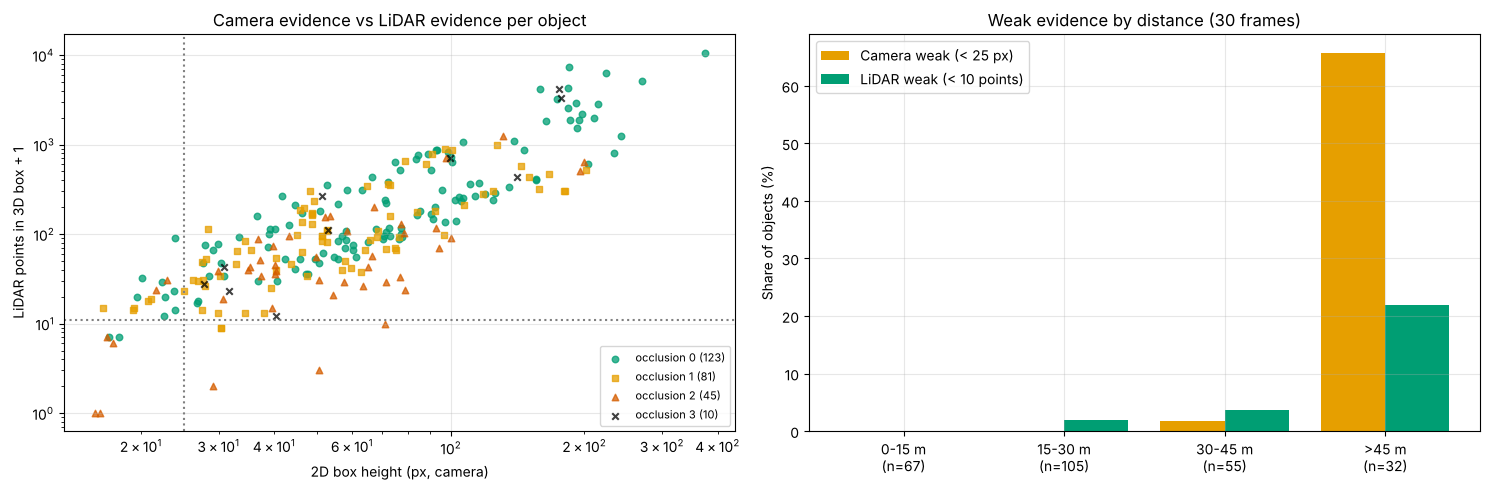

--- Joint weakness (text summary, measured on 259 objects) ---
  P(camera weak) = 0.085, P(LiDAR weak) = 0.042
  P(both weak) measured = 0.023; if independent it would be 0.0036 -> 6x more often than independence predicts
  LiDAR weak by KITTI occlusion level: 0: 2 %, 1: 2 %, 2: 16 %, 3: 0 %
  Distance and occlusion are common causes: they weaken camera AND LiDAR on the same objects.


In [11]:
obj['camera_weak'] = obj['box_height_px'] < 25
obj['lidar_weak'] = obj['lidar_points'] < 10
p_c, p_l = obj['camera_weak'].mean(), obj['lidar_weak'].mean()
p_both = (obj['camera_weak'] & obj['lidar_weak']).mean()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for occ, mk in zip(range(4), ['o', 's', '^', 'x']):
    s = obj[obj['occluded'] == occ]
    axes[0].scatter(s['box_height_px'], s['lidar_points'] + 1, marker=mk, s=22, alpha=0.75,
                    color=OKABE_ITO[[2, 0, 5, 7][occ]], label=f'occlusion {occ} ({len(s)})')
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].axvline(25, color='grey', ls=':'); axes[0].axhline(11, color='grey', ls=':')
axes[0].set_xlabel('2D box height (px, camera)'); axes[0].set_ylabel('LiDAR points in 3D box + 1')
axes[0].set_title('Camera evidence vs LiDAR evidence per object'); axes[0].legend(fontsize=8)

bins = [0, 15, 30, 45, 90]
obj['range_bin'] = pd.cut(obj['distance_m'], bins, labels=['0-15 m', '15-30 m', '30-45 m', '>45 m'])
tab = obj.groupby('range_bin', observed=True)[['camera_weak', 'lidar_weak']].mean() * 100
tab['n'] = obj.groupby('range_bin', observed=True).size()
xx = np.arange(len(tab))
axes[1].bar(xx - 0.2, tab['camera_weak'], 0.4, color=SENSOR_COLOURS['Camera'], label='Camera weak (< 25 px)')
axes[1].bar(xx + 0.2, tab['lidar_weak'], 0.4, color=SENSOR_COLOURS['LiDAR'], label='LiDAR weak (< 10 points)')
axes[1].set_xticks(xx); axes[1].set_xticklabels([f"{i}\n(n={n})" for i, n in zip(tab.index, tab['n'])])
axes[1].set_ylabel('Share of objects (%)'); axes[1].set_title('Weak evidence by distance (30 frames)'); axes[1].legend()
plt.tight_layout(); plt.show()

occ_tab = obj.groupby('occluded')['lidar_weak'].mean() * 100
print("--- Joint weakness (text summary, measured on", len(obj), "objects) ---")
print(f"  P(camera weak) = {p_c:.3f}, P(LiDAR weak) = {p_l:.3f}")
print(f"  P(both weak) measured = {p_both:.3f}; if independent it would be {p_c * p_l:.4f} "
      f"-> {p_both / max(p_c * p_l, 1e-9):.0f}x more often than independence predicts")
print("  LiDAR weak by KITTI occlusion level: " + ", ".join(f"{k}: {v:.0f} %" for k, v in occ_tab.items()))
print("  Distance and occlusion are common causes: they weaken camera AND LiDAR on the same objects.")

---
## Part 6: Radar — concept only (KITTI has no radar)

KITTI, like many early datasets, contains no radar, so this notebook cannot show radar measurements. Datasets with radar include nuScenes (conventional radar, Caesar et al., 2020), View-of-Delft and K-Radar (4D radar) and MAN TruckScenes (360° 4D radar). The physics needed to reason about radar is short.

A radar measures the **Doppler shift** of the reflected wave. For a target with radial velocity $v_r$ and carrier wavelength $\lambda = c / f_c$:

$$ f_D = \frac{2 v_r}{\lambda} $$

Automotive radars operate in the 76–81 GHz band (77 GHz → λ ≈ 3.9 mm).

In [12]:
c = 299_792_458.0
f_c = 77e9
lam = c / f_c
v = np.array([1.0, 5.0, 13.9, 27.8, 36.1])         # m/s (13.9 m/s = 50 km/h, 27.8 = 100 km/h, 36.1 = 130 km/h)
f_d = 2 * v / lam
print(f"Wavelength at 77 GHz: {lam*1e3:.2f} mm")
for vi, fi in zip(v, f_d):
    print(f"  radial velocity {vi:5.1f} m/s ({vi*3.6:5.1f} km/h) -> Doppler shift {fi/1e3:6.2f} kHz")
print("A camera or ToF LiDAR must estimate velocity by differencing positions over frames (noisier, delayed);"
      " radar (and FMCW LiDAR) measure the radial component in a single measurement."
      " The tangential component (crossing traffic) is NOT measured by Doppler.")

Wavelength at 77 GHz: 3.89 mm
  radial velocity   1.0 m/s (  3.6 km/h) -> Doppler shift   0.51 kHz
  radial velocity   5.0 m/s ( 18.0 km/h) -> Doppler shift   2.57 kHz
  radial velocity  13.9 m/s ( 50.0 km/h) -> Doppler shift   7.14 kHz
  radial velocity  27.8 m/s (100.1 km/h) -> Doppler shift  14.28 kHz
  radial velocity  36.1 m/s (130.0 km/h) -> Doppler shift  18.54 kHz
A camera or ToF LiDAR must estimate velocity by differencing positions over frames (noisier, delayed); radar (and FMCW LiDAR) measure the radial component in a single measurement. The tangential component (crossing traffic) is NOT measured by Doppler.


### 4D imaging radar

Conventional automotive radars resolve range, azimuth and radial velocity. **4D imaging radars** add **elevation** using larger virtual antenna arrays (MIMO), producing sparse point clouds similar to a low-resolution LiDAR but robust to weather. This helps to separate, for example, an overhead sign gantry from a stopped vehicle. Public datasets include K-Radar (Paek et al., NeurIPS 2022 Datasets & Benchmarks), View-of-Delft (Palffy et al., IEEE RA-L 2022) and MAN TruckScenes (Fent et al., NeurIPS 2024 Datasets & Benchmarks).

### Weather: what this dataset cannot show

KITTI was recorded in daylight and dry weather, so it says nothing about rain, fog, snow or night. The qualitative tendencies are well established, but their size depends on the product and the intensity of the condition, and must be measured on data that contains those conditions (for example the adverse-weather recordings of Bijelic et al., 2020, or K-Radar).

| Condition | Camera | LiDAR | Radar |
|---|---|---|---|
| Night | Strongly degraded without illumination | Largely unaffected (active sensor) | Unaffected |
| Low sun, glare, tunnel exits | Saturation, lost contrast | Sun noise possible | Unaffected |
| Rain, spray | Drops on lens, lower contrast | Attenuation, clutter from spray | Small range loss |
| Fog | Strong contrast loss | Strong attenuation, backscatter | Small effect |
| Snow, ice on sensor cover | Blocked | Blocked | Degraded, blocked if thick |

> This table is qualitative; no numbers are implied. Replace it with measured detection rates per condition in a real sensor evaluation.

---
## Part 7: How much does redundancy buy?

If each of $n$ sensors independently misses an object with probability $p_i$, all of them miss with probability $\prod_i p_i$. Part 5 measured that the camera and the LiDAR are weak on the **same** objects far more often than independence predicts. Reliability engineering models such dependence with the **β-factor model**: a fraction β of each sensor's miss probability is common to all sensors.

> **Illustrative data:** the miss probabilities and β values below are synthetic, chosen for teaching. The measured joint-weakness ratio from Part 5 is used only to show which β range is plausible.

  beta=0.0   sensors=Camera                 P(all miss) = 5.00e-02
  beta=0.0   sensors=Camera+LiDAR           P(all miss) = 1.50e-03
  beta=0.0   sensors=Camera+LiDAR+Radar     P(all miss) = 1.20e-04
  beta=0.01  sensors=Camera                 P(all miss) = 5.00e-02
  beta=0.01  sensors=Camera+LiDAR           P(all miss) = 1.78e-03
  beta=0.01  sensors=Camera+LiDAR+Radar     P(all miss) = 4.18e-04
  beta=0.1   sensors=Camera                 P(all miss) = 5.00e-02
  beta=0.1   sensors=Camera+LiDAR           P(all miss) = 4.27e-03
  beta=0.1   sensors=Camera+LiDAR+Radar     P(all miss) = 3.10e-03


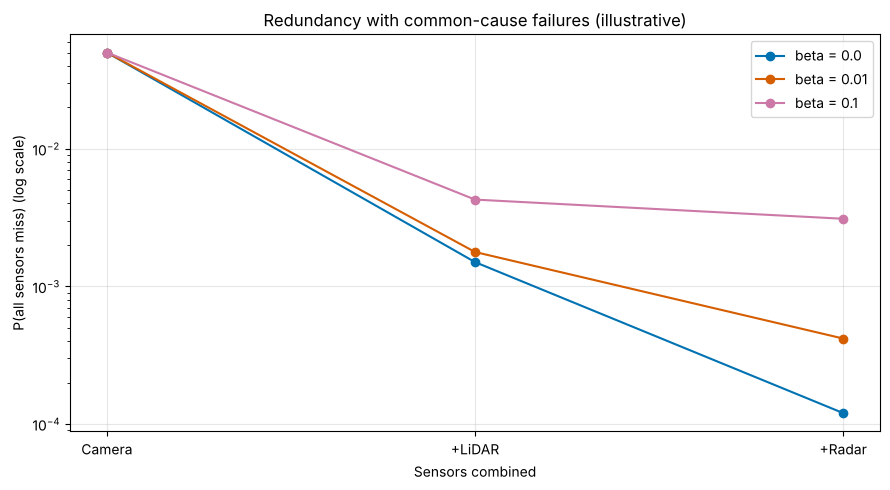

Adding LiDAR and radar reduces P(all miss) by 417x if failures are independent, but only by 16x with beta = 0.1.
The KITTI joint-weakness rates of Part 5 correspond to beta ~ 0.46 for camera + LiDAR ('weak evidence', not 'missed detection', so treat this as an indication only).


In [13]:
p_miss = {'Camera': 0.05, 'LiDAR': 0.03, 'Radar': 0.08}    # illustrative per-object miss probabilities

def p_all_miss(ps, beta):
    """beta-factor model (rare-event approximation): a common-cause part Q_cc = beta * min(p)
    defeats all sensors at once; the remaining parts (p_i - Q_cc) fail independently."""
    ps = np.asarray(ps, float)
    q_cc = beta * ps.min()
    return q_cc + np.prod(ps - q_cc)

combos = [['Camera'], ['Camera', 'LiDAR'], ['Camera', 'LiDAR', 'Radar']]
betas = [0.0, 0.01, 0.1]
fig, ax = plt.subplots(figsize=(9, 5))
for b, col in zip(betas, OKABE_ITO[4:7]):
    vals = [p_all_miss([p_miss[s] for s in cmb], b) for cmb in combos]
    ax.semilogy(range(1, 4), vals, 'o-', color=col, label=f'beta = {b}')
    for k, val in enumerate(vals):
        print(f"  beta={b:<5} sensors={'+'.join(combos[k]):22s} P(all miss) = {val:.2e}")
ax.set_xticks([1, 2, 3]); ax.set_xticklabels(['Camera', '+LiDAR', '+Radar'])
ax.set_xlabel('Sensors combined'); ax.set_ylabel('P(all sensors miss) (log scale)')
ax.set_title('Redundancy with common-cause failures (illustrative)'); ax.legend()
plt.tight_layout(); plt.show()

gain_indep = p_all_miss([p_miss['Camera']], 0) / p_all_miss([p_miss[s] for s in combos[2]], 0)
gain_cc = p_all_miss([p_miss['Camera']], 0.1) / p_all_miss([p_miss[s] for s in combos[2]], 0.1)
# beta that reproduces the measured camera/LiDAR joint-weakness on KITTI (two-sensor case)
beta_meas = (p_both - p_c * p_l) / max(min(p_c, p_l), 1e-9)
print(f"Adding LiDAR and radar reduces P(all miss) by {gain_indep:,.0f}x if failures are independent, "
      f"but only by {gain_cc:.0f}x with beta = 0.1.")
print(f"The KITTI joint-weakness rates of Part 5 correspond to beta ~ {beta_meas:.2f} for camera + LiDAR "
      "('weak evidence', not 'missed detection', so treat this as an indication only).")

---
## Safety perspective

- Each modality has **performance limitations** that are not faults: a pedestrian at 49 m behind a parked car that returns one LiDAR point is a correct measurement of a hard situation. Under ISO 21448:2022 these are *performance insufficiencies*, and the conditions that reveal them (distance, occlusion, glare, fog, retro-reflective signs) are *triggering conditions*.
- Diverse sensors **support** a safety argument — for ISO 26262 (random hardware faults, ASIL decomposition into sufficiently independent elements per ISO 26262-9) and for ISO 21448 (mitigating performance insufficiencies) — but only if the independence assumption is justified. Part 5 showed on real data that distance and occlusion degrade camera and LiDAR together.
- Neither standard *mandates* a particular sensor set; the required evidence follows from the hazard analysis. For the course's recurring AEB example (urban sub-scope up to 60 km/h), the relevant question is whether a pedestrian is reliably seen at the distance needed to brake, not which sensor is "best".

## In industry

**Work product:** the *sensor set selection and sensor requirement specification* (inputs to the technical safety concept and the SOTIF analysis of known hazardous scenarios). Typically produced by the **perception system architect** with the sensor suppliers, reviewed by the **functional safety and SOTIF managers**.

What reviewers look for:
- Requirements stated per object class and distance (e.g. minimum points or pixels on a 1.2 m child at the braking distance for 60 km/h), not as datasheet range.
- Measured coverage, density and reflectance-dependence from recorded data of the target ODD (as in Parts 2–5), with the reflectivity and conditions stated.
- Field-of-view and blind-zone analysis (camera ±40° vs 360° LiDAR here; no LiDAR coverage above ~2° elevation).
- A dependent-failure analysis between sensors: shared causes such as distance, occlusion, weather, contamination, mounting position, power and time base — supported by data on joint weaknesses, not only by an independence assumption.
- Explicit statements of what the evaluation data cannot show (here: radar, weather, night).

Continue with: [03 LiDAR and point clouds](03_lidar_point_clouds.ipynb) · [04_SOTIF_ISO21448/02 — Triggering conditions](../04_SOTIF_ISO21448/02_triggering_conditions_and_scenarios.ipynb) · [03_Functional_Safety_ISO26262/01 — ISO 26262 fundamentals](../03_Functional_Safety_ISO26262/01_iso26262_fundamentals.ipynb).

## Key takeaways

- Camera = dense semantics without direct depth; LiDAR = precise but sparse 3D with reflectance; radar = weather-robust range and radial velocity with low angular resolution (not in KITTI).
- In a real KITTI frame only a few per cent of image pixels receive a LiDAR point, and the upper part of the image has none at all; most LiDAR returns lie outside the camera's field of view.
- Measured on KITTI: points on objects fall roughly with 1/d², ground returns faster (about 1/d³); the camera has a roughly constant number of pixels per LiDAR point at all distances.
- Distant and occluded objects are weak for both sensors at once: the measured joint weakness is far above what independence predicts.
- Redundancy helps only as far as failures are independent; quantify the dependence instead of assuming it.
- What a dataset cannot show (radar, weather, night for KITTI) must be stated, not filled with invented numbers.

## Self-assessment

1. Which sensor works best in fog, and why?
2. Why can a conventional radar struggle to distinguish a stopped vehicle from an overhead sign gantry, and what changes with 4D imaging radar?
3. In the showcase frame, roughly what share of image pixels has a LiDAR point? What does that imply for detecting small objects with LiDAR alone?
4. Why does ground-return density fall faster with range than the number of points on a car's rear?
5. Three sensors each miss an object with probability 0.05. What is P(all miss) if failures are independent? Why did the KITTI data suggest the real value is higher?
6. Give two reasons, visible in this notebook, why a pedestrian can be "missed" by LiDAR although the sensor works as specified.

<details>
<summary>Show answers</summary>

1. Radar: millimetre waves are much less attenuated and scattered by fog droplets than visible or near-infrared light.
2. Conventional radar has little or no elevation resolution, so both appear as strong static returns at similar range and azimuth. 4D imaging radar measures elevation and can separate them by height.
3. A few per cent (the exact value is printed in Part 2). Small or distant objects receive only a handful of points, so classification from LiDAR alone is hard; the camera supplies the semantics.
4. A surface facing the sensor intercepts beams at near-normal incidence, so point spacing grows linearly with range in both directions (1/d²). The ground is hit at a grazing angle: the distance between consecutive rings grows with d²/h, so the density falls roughly with 1/d³.
5. 0.05³ = 1.25 × 10⁻⁴. On KITTI, objects that are weak for the camera are much more often also weak for the LiDAR (common causes: distance, occlusion), so failures are positively correlated and the joint miss probability is higher.
6. Distance (few points per object at 40–50 m), occlusion by parked cars, and the limited vertical field of view near the vehicle. None of these is a fault: they are performance limitations and triggering conditions in the sense of ISO 21448.

</details>

## References

1. Geiger, A., Lenz, P., Stiller, C., Urtasun, R. (2013). Vision meets robotics: The KITTI dataset. *The International Journal of Robotics Research* 32(11), 1231–1237. https://doi.org/10.1177/0278364913491297
2. Geiger, A., Lenz, P., Urtasun, R. (2012). Are we ready for autonomous driving? The KITTI vision benchmark suite. *CVPR 2012*. https://doi.org/10.1109/CVPR.2012.6248074
3. ISO 21448:2022. *Road vehicles — Safety of the intended functionality.* https://www.iso.org/standard/77490.html
4. ISO 26262-9:2018. *Road vehicles — Functional safety — Part 9: ASIL-oriented and safety-oriented analyses.* https://www.iso.org/standard/68391.html
5. Royo, S., Ballesta-Garcia, M. (2019). An Overview of Lidar Imaging Systems for Autonomous Vehicles. *Applied Sciences* 9(19), 4093. https://doi.org/10.3390/app9194093
6. Bijelic, M. et al. (2020). Seeing Through Fog Without Seeing Fog: Deep Multimodal Sensor Fusion in Unseen Adverse Weather. *CVPR 2020*. https://doi.org/10.1109/CVPR42600.2020.01170
7. Caesar, H. et al. (2020). nuScenes: A multimodal dataset for autonomous driving. *CVPR 2020*. https://doi.org/10.1109/CVPR42600.2020.01164
8. Paek, D.-H., Kong, S.-H., Wijaya, K. T. (2022). K-Radar: 4D Radar Object Detection for Autonomous Driving in Various Weather Conditions. NeurIPS Datasets & Benchmarks. arXiv:2206.08171
9. Palffy, A. et al. (2022). Multi-class Road User Detection with 3+1D Radar in the View-of-Delft Dataset. *IEEE Robotics and Automation Letters* 7(2), 4961–4968. https://doi.org/10.1109/LRA.2022.3147324
10. Fent, F. et al. (2024). MAN TruckScenes: A multimodal dataset for autonomous trucking in diverse conditions. NeurIPS Datasets & Benchmarks. arXiv:2407.07462
11. Reuters (Nov 2024), reported by LEDinside: Hesai to halve LiDAR prices with ATX. https://www.ledinside.com/node/34820

---
**Navigation:** ← [01 SAE levels and ODD](01_sae_levels_and_odd.ipynb) · [Module index](README.md) · [03 LiDAR and point clouds](03_lidar_point_clouds.ipynb) →